This script showcases batch inference ML techniques for inventory management.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [3]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/alinoranianesfahani/dataco-smart-supply-chain-for-big-data-analysis/code
    
# load single-store sales data
DataCoSupplyChainDataset = pd.read_csv(
    data_dir / 'DataCoSupplyChainDataset.csv',
    encoding='Latin-1',
    low_memory=False
)

# Wrangle

In [4]:
df = DataCoSupplyChainDataset.copy()

# prepare dates and demand quantities
df["order_date"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

df = df[df['order_date'] <= '2017-09-30']

df["demand"] = pd.to_numeric(
    df["Order Item Quantity"],
    errors="coerce"
)

# aggregate demand by product and date
daily_demand_product = (
    df.dropna(subset=["order_date", "Product Card Id", "demand"])
    .assign(date=lambda x: x["order_date"].dt.normalize())
    .groupby(
        ["Product Card Id", "date"],
        as_index=False
    )["demand"]
    .sum()
    .rename(columns={"Product Card Id": "product_id"})
    .sort_values(["product_id", "date"])
)

print("\ndaily demand shape:", daily_demand_product.shape)
print(daily_demand_product.head())


daily demand shape: (22075, 3)
   product_id       date  demand
0          19 2017-04-24       1
1          19 2017-04-26       1
2          19 2017-05-03       1
3          19 2017-05-04       1
4          19 2017-05-06       1


In [5]:
# create a complete daily date range
all_dates = pd.date_range(
    start=daily_demand_product["date"].min(),
    end=daily_demand_product["date"].max(),
    freq="D"
)

# create every product-date combination
products = daily_demand_product["product_id"].unique()

full_index = pd.MultiIndex.from_product(
    [products, all_dates],
    names=["product_id", "date"]
)

# fill dates without recorded orders with zero demand
daily_demand_product = (
    daily_demand_product
    .set_index(["product_id", "date"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

daily_demand_product["demand"] = daily_demand_product["demand"].astype(int)

In [6]:
# inspect the completed time series
print("shape:", daily_demand_product.shape)
print("\nproducts:", daily_demand_product["product_id"].nunique())
print("\ndate range:", daily_demand_product["date"].min(), "to", daily_demand_product["date"].max())
print("\nmissing values:\n", daily_demand_product.isna().sum())

shape: (98294, 3)

products: 98

date range: 2015-01-01 00:00:00 to 2017-09-29 00:00:00

missing values:
 product_id    0
date          0
demand        0
dtype: int64


# Explore daily demand

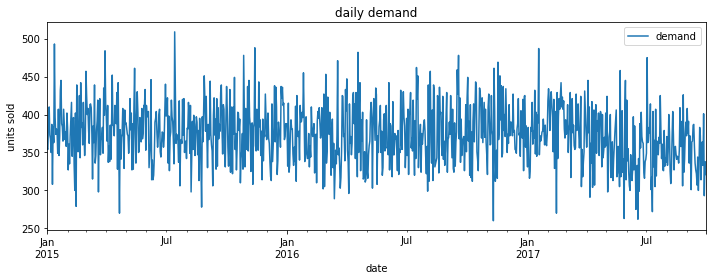

In [7]:
daily_demand = daily_demand_product.groupby("date")[["demand"]].sum()

daily_demand.plot(figsize=(10, 4))
plt.title("daily demand")
plt.ylabel("units sold")
plt.tight_layout()
plt.show()

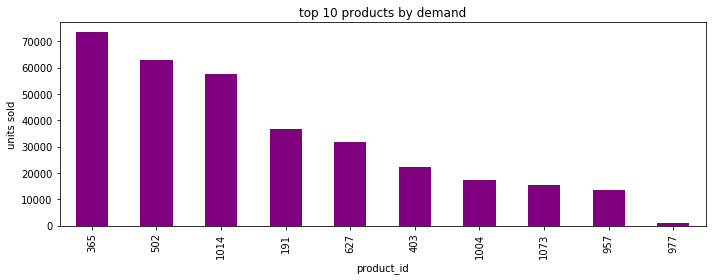

In [8]:
daily_demand_product.groupby("product_id")["demand"].sum().nlargest(10).plot(
    kind="bar", figsize=(10, 4), color = 'purple'
)
plt.title("top 10 products by demand")
plt.ylabel("units sold")
plt.tight_layout()
plt.show()

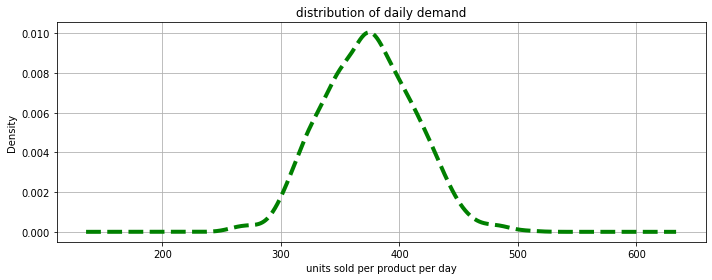

In [9]:
# demand distribution
daily_demand["demand"].plot(
    kind="kde", figsize=(10, 4), title="distribution of daily demand", lw=4, ls='--', color='green'
)

plt.xlabel("units sold per product per day")
plt.grid()
plt.tight_layout()
plt.show()

In [10]:
daily_demand["demand"].describe()

count    1003.000000
mean      373.786640
std        38.885167
min       260.000000
25%       347.000000
50%       374.000000
75%       401.000000
max       509.000000
Name: demand, dtype: float64

# Feature engineering

In [11]:
daily_demand_product = daily_demand_product.sort_values(["product_id", "date"])

daily_demand_product["lag_1"] = daily_demand_product.groupby("product_id")["demand"].shift(1)
daily_demand_product["lag_7"] = daily_demand_product.groupby("product_id")["demand"].shift(7)

daily_demand_product["rolling_7"] = (
    daily_demand_product.groupby("product_id")["demand"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

daily_demand_product = daily_demand_product.dropna().reset_index(drop=True)

# Split into train and test

In [12]:
# split each product chronologically
features = ["lag_1", "lag_7", "rolling_7"]
target = "demand"

train_parts = []
test_parts = []
skipped_products = []

for product_id, group in daily_demand_product.groupby("product_id"):
    group = group.sort_values("date")

    if len(group) < 74:
        skipped_products.append(product_id)
        continue

    split_idx = int(len(group) * 0.8)

    train_parts.append(group.iloc[:split_idx])
    test_parts.append(group.iloc[split_idx:])

# combine product-level splits
train = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

# summarize the split
print("products modeled:", train["product_id"].nunique())
print("products skipped:", len(skipped_products))
print("training rows:", len(train))
print("testing rows:", len(test))
print("training date range:", train["date"].min(), "to", train["date"].max())
print("testing date range:", test["date"].min(), "to", test["date"].max())

products modeled: 98
products skipped: 0
training rows: 78008
testing rows: 19600
training date range: 2015-01-08 00:00:00 to 2017-03-13 00:00:00
testing date range: 2017-03-14 00:00:00 to 2017-09-29 00:00:00


# ML forecasting model fit
For each product:  
LightGBM  
XGBoost  
Random Forest  

For ARIMA examples, see Data-Science-Portfolio/m5-forecasting-accuracy/01.  Demand forecasting (Naive, ARIMA, LightGBM, XGBoost)

In [13]:
forecast_model_results = {}

## LightGBM

In [14]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

results = []
models = {}

for product_id, group in train.groupby("product_id"):
    test_group = test[test["product_id"] == product_id]

    if test_group.empty:
        continue

    model = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        verbosity=-1
    )

    model.fit(group[features], group[target])

    predictions = model.predict(test_group[features]).clip(min=0)

    results.append({
        "product_id": product_id,
        "mae": mean_absolute_error(test_group[target], predictions),
        "actual_demand": test_group[target].sum(),
        "predicted_demand": predictions.sum()
    })

    models[product_id] = model

results = pd.DataFrame(results)

print("products modeled:", len(results))
print("average product MAE:", results["mae"].mean())

forecast_model_results['LightGBM'] = [len(results), results["mae"].mean()]

products modeled: 98
average product MAE: 1.509056478463627


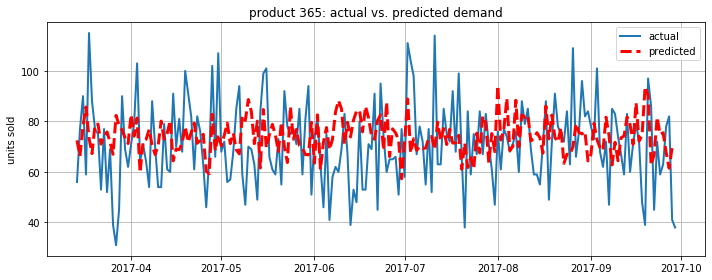

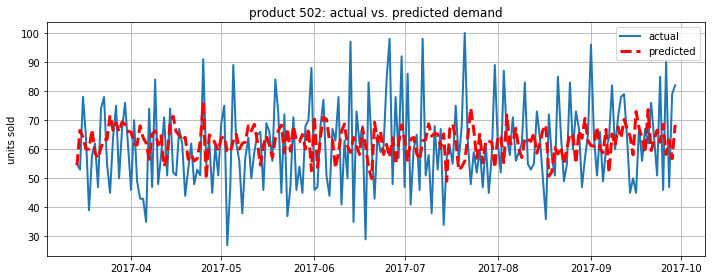

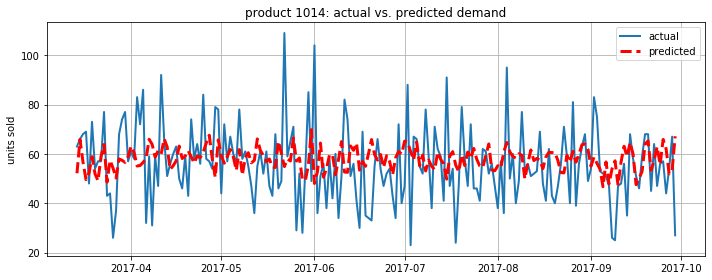

In [15]:
top_products = results.nlargest(3, "mae")["product_id"]

for product_id in top_products:
    product_test = test[test["product_id"] == product_id].copy()
    model = models[product_id]

    product_test["predicted"] = model.predict(
        product_test[features]
    ).clip(min=0)

    plt.figure(figsize=(10, 4))
    plt.plot(product_test["date"], product_test["demand"], label="actual", lw=2)
    plt.plot(product_test["date"], product_test["predicted"], label="predicted", ls="--", lw=3, color="red")
    plt.title(f"product {product_id}: actual vs. predicted demand")
    plt.ylabel("units sold")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

## LightGBM tuning example
Compare results before and after tuning hyperparameters.

In [16]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
import lightgbm as lgb

param_grid = {
    "n_estimators": [100, 200, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 5, 7],
    "num_leaves": [7, 15, 31]
}

comparison = None

for product_id in train["product_id"].unique():
    product_train = train[train["product_id"] == product_id].sort_values("date")
    product_test = test[test["product_id"] == product_id].sort_values("date")

    if len(product_train) < 60 or len(product_test) < 14:
        continue

    X_train = product_train[features]
    y_train = product_train[target]
    X_test = product_test[features]
    y_test = product_test[target]

    # baseline
    baseline = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        verbosity=-1
    )
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test).clip(min=0)
    baseline_mae = mean_absolute_error(y_test, baseline_pred)

    # tune
    search = GridSearchCV(
        lgb.LGBMRegressor(random_state=42, verbosity=-1),
        param_grid,
        scoring="neg_mean_absolute_error",
        cv=TimeSeriesSplit(n_splits=3),
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    tuned_pred = search.best_estimator_.predict(X_test).clip(min=0)
    tuned_mae = mean_absolute_error(y_test, tuned_pred)

    improvement = (baseline_mae - tuned_mae) / baseline_mae if baseline_mae else 0

    print(
        f"product {product_id}: baseline MAE={baseline_mae:.3f}, "
        f"tuned MAE={tuned_mae:.3f}, improvement={improvement:.1%}"
    )

    if improvement >= 0.05:
        comparison = pd.DataFrame({
            "model": ["baseline", "tuned"],
            "test_mae": [baseline_mae, tuned_mae]
        })

        print("\nmeaningful improvement found")
        print("best parameters:", search.best_params_)
        display(comparison)
        break

product 19: baseline MAE=0.320, tuned MAE=0.320, improvement=0.0%
product 24: baseline MAE=1.155, tuned MAE=1.155, improvement=0.0%
product 35: baseline MAE=0.325, tuned MAE=0.325, improvement=0.0%
product 37: baseline MAE=1.010, tuned MAE=0.945, improvement=6.4%

meaningful improvement found
best parameters: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'num_leaves': 7}


,model,test_mae
0,baseline,1.009504
1,tuned,0.945227


Tuning the hyperparameters can be computationally expensive while not producing meaningful results.  
However, at times it *does* decrease the MAE.   
Discretion must used when applying hyperparamter tuning.

## XGBoost

In [17]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

xgb_results = {}
xgb_models = {}

for product_id, group in train.groupby("product_id"):
    test_group = test[test["product_id"] == product_id]

    if test_group.empty:
        continue

    model = XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(group[features], group[target])
    predictions = model.predict(test_group[features]).clip(min=0)

    actual = test_group[target]

    xgb_results[product_id] = {
        "mae": mean_absolute_error(actual, predictions),
        "actual_demand": actual.sum(),
        "predicted_demand": predictions.sum()
    }

    xgb_models[product_id] = model

xgb_metrics = pd.DataFrame.from_dict(xgb_results, orient="index")
xgb_metrics.index.name = "product_id"
xgb_metrics = xgb_metrics.reset_index()

display(xgb_metrics.head())

forecast_model_results['XGBoost'] = [len(xgb_metrics), xgb_metrics["mae"].mean()]

,product_id,mae,actual_demand,predicted_demand
0,19,0.321373,64,0.596961
1,24,1.156313,231,0.596961
2,35,0.326433,65,0.596961
3,37,0.986319,38,176.650833
4,44,0.980703,63,164.202087


## Random forest

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

rf_results = {}
rf_models = {}

for product_id, group in train.groupby("product_id"):
    test_group = test[test["product_id"] == product_id]

    if test_group.empty:
        continue

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(group[features], group[target])
    predictions = model.predict(test_group[features]).clip(min=0)

    actual = test_group[target]

    rf_results[product_id] = {
        "mae": mean_absolute_error(actual, predictions),
        "actual_demand": actual.sum(),
        "predicted_demand": predictions.sum()
    }

    rf_models[product_id] = model

rf_metrics = pd.DataFrame.from_dict(rf_results, orient="index")
rf_metrics.index.name = "product_id"
rf_metrics = rf_metrics.reset_index()

display(rf_metrics.head())

forecast_model_results['Random Forest'] = [len(rf_metrics), rf_metrics["mae"].mean()]

,product_id,mae,actual_demand,predicted_demand
0,19,0.320000,64,0.000000
1,24,1.155000,231,0.000000
2,35,0.325000,65,0.000000
3,37,0.994971,38,177.909633
4,44,0.963501,63,160.452745


## ML forecasting results

In [19]:
res = pd.DataFrame(forecast_model_results).T
res.columns = ["Number of Products","Avg MAE"]
print(f"With the lowest MAE, the winner is {res['Avg MAE'].idxmin()}")
print("Note this is just an example, and in the real world we'd use many different metrics to choose the best model.")
res

With the lowest MAE, the winner is XGBoost
Note this is just an example, and in the real world we'd use many different metrics to choose the best model.


,Number of Products,Avg MAE
LightGBM,98.0,1.509056
XGBoost,98.0,1.493721
Random Forest,98.0,1.496226


# Replenishment + order quantity optimization
## Lead time, safety stock, reorder point

In [20]:
lead_time_days = 7 # assumption

replenishment = (
    daily_demand_product.groupby("product_id")
    .agg(
        avg_daily_demand=("demand", "mean"),
        demand_std=("demand", "std"),
        total_demand=("demand", "sum"),
        days_observed=("demand", "count")
    )
    .reset_index()
)

replenishment["lead_time_demand"] = (
    replenishment["avg_daily_demand"] * lead_time_days
)

replenishment["safety_stock"] = (
    replenishment["lead_time_demand"] * 0.20 # assumption
).round().astype(int)

replenishment["reorder_point"] = (
    replenishment["lead_time_demand"] + replenishment["safety_stock"]
).apply(lambda x: int(__import__("math").ceil(x)))

display(
    replenishment.sort_values("reorder_point", ascending=False).head(10)
)

,product_id,avg_daily_demand,demand_std,total_demand,days_observed,lead_time_demand,safety_stock,reorder_point
34,365,73.252008,16.720996,72959,996,512.764056,103,616
36,502,62.704819,15.938173,62454,996,438.933735,88,527
95,1014,57.464859,14.804921,57235,996,402.254016,80,483
14,191,36.452811,12.103689,36307,996,255.169679,51,307
43,627,31.552209,10.651646,31426,996,220.865462,44,265
35,403,22.144578,4.855622,22056,996,155.012048,31,187
94,1004,17.247992,4.239767,17179,996,120.735944,24,145
97,1073,15.413655,4.078818,15352,996,107.895582,22,130
90,957,13.658635,3.728194,13604,996,95.610442,19,115
40,572,0.875502,1.844879,872,996,6.128514,1,8


## Recommended order qty

In [21]:
review_period_days = 7  # assumption

replenishment["max_inventory"] = (
    replenishment["avg_daily_demand"]
    * (lead_time_days + review_period_days)
    + replenishment["safety_stock"]
).apply(lambda x: int(__import__("math").ceil(x)))

# example inventory position: assume current stock and on-order quantities are unknown
replenishment["current_inventory"] = 0  # placeholder
replenishment["on_order"] = 0  # placeholder

replenishment["inventory_position"] = (
    replenishment["current_inventory"] + replenishment["on_order"]
)

replenishment["recommended_order_qty"] = (
    replenishment["max_inventory"] - replenishment["inventory_position"]
).clip(lower=0)

display(
    replenishment[
        [
            "product_id",
            "avg_daily_demand",
            "reorder_point",
            "max_inventory",
            "inventory_position",
            "recommended_order_qty",
        ]
    ].sort_values("recommended_order_qty", ascending=False).head(10)
)

,product_id,avg_daily_demand,reorder_point,max_inventory,inventory_position,recommended_order_qty
34,365,73.252008,616,1129,0,1129
36,502,62.704819,527,966,0,966
95,1014,57.464859,483,885,0,885
14,191,36.452811,307,562,0,562
43,627,31.552209,265,486,0,486
35,403,22.144578,187,342,0,342
94,1004,17.247992,145,266,0,266
97,1073,15.413655,130,238,0,238
90,957,13.658635,115,211,0,211
81,885,0.961847,8,15,0,15


## Simulate historical data
Use the framework we built above.

In [22]:
simulation_results = []

for product_id, group in daily_demand_product.groupby("product_id"):
    group = group.sort_values("date").reset_index(drop=True)

    policy = replenishment.loc[
        replenishment["product_id"] == product_id
    ]

    if policy.empty:
        continue

    reorder_point = int(policy["reorder_point"].iloc[0])
    max_inventory = int(policy["max_inventory"].iloc[0])

    inventory = max_inventory
    pending_orders = {}
    stockout_days = 0
    units_short = 0
    inventory_total = 0
    orders_placed = 0

    for day, row in group.iterrows():
        inventory += pending_orders.pop(day, 0)

        demand = int(row["demand"])
        fulfilled = min(inventory, demand)
        inventory -= fulfilled

        units_short += demand - fulfilled
        stockout_days += int(demand > fulfilled)
        inventory_total += inventory

        # review inventory only at the scheduled interval
        if day % review_period_days == 0:
            on_order = sum(pending_orders.values())
            inventory_position = inventory + on_order

            if inventory_position <= reorder_point:
                order_qty = max_inventory - inventory_position

                if order_qty > 0:
                    arrival_day = day + lead_time_days
                    pending_orders[arrival_day] = (
                        pending_orders.get(arrival_day, 0) + order_qty
                    )
                    orders_placed += 1

    simulation_results.append({
        "product_id": product_id,
        "stockout_days": stockout_days,
        "units_short": units_short,
        "avg_inventory": inventory_total / len(group),
        "orders_placed": orders_placed,
        "total_demand": group["demand"].sum()
    })

simulation_metrics = pd.DataFrame(simulation_results)

In [23]:
display(
    pd.DataFrame([{
        "total_demand": simulation_metrics["total_demand"].sum(),
        "units_short": simulation_metrics["units_short"].sum(),
        "demand_unfulfilled_pct": (
            simulation_metrics["units_short"].sum()
            / simulation_metrics["total_demand"].sum() * 100
        ).round(2),
        "stockout_days": simulation_metrics["stockout_days"].sum(),
        "stockout_days_pct": (
            simulation_metrics["stockout_days"].sum()
            / daily_demand_product.groupby("product_id")["date"].nunique().sum()
            * 100
        ).round(2),
        "avg_inventory_per_product": simulation_metrics["avg_inventory"].mean(),
        "total_orders": simulation_metrics["orders_placed"].sum()
    }])
)

,total_demand,units_short,demand_unfulfilled_pct,stockout_days,stockout_days_pct,avg_inventory_per_product,total_orders
0,372306,65130,17.49,6915,7.08,19.366261,3853


### Next steps
Is an unfulfilled_pct <= P% ok?  
Next step would be to determine thresholds of what's acceptable.  
Then, adjust the model to meet the objective.

# Inventory optimization
## Grid search (exhaustive search)
Can be extremely expensive for large datasets

This approach minimizes unfulfilled demand by evaluating combinations of safety-stock percentages and inventory review periods. Each policy is simulated using demand, lead times, reorder points, and maximum inventory levels. The resulting policies are compared by unfulfilled demand, stockout frequency, and average inventory.

In [24]:
import math

safety_stock_pcts = [0.10, 0.20, 0.30, 0.50]
review_periods = [3, 7, 14]

optimization_results = []

for safety_pct in safety_stock_pcts:
    for review_days in review_periods:

        # recalculate policy for each scenario
        policy = replenishment[[
            "product_id", "avg_daily_demand", "lead_time_demand"
        ]].copy()

        policy["safety_stock"] = (
            policy["lead_time_demand"] * safety_pct
        ).round().astype(int)

        policy["reorder_point"] = (
            policy["lead_time_demand"] + policy["safety_stock"]
        ).apply(math.ceil)

        policy["max_inventory"] = (
            policy["avg_daily_demand"] * (lead_time_days + review_days)
            + policy["safety_stock"]
        ).apply(math.ceil)

        # simulate each product under this policy
        total_short = 0
        total_demand = 0
        total_stockout_days = 0
        total_product_days = 0
        total_inventory = 0
        total_orders = 0

        for product_id, group in daily_demand_product.groupby("product_id"):
            group = group.sort_values("date").reset_index(drop=True)
            p = policy.loc[policy["product_id"] == product_id]

            if p.empty:
                continue

            reorder_point = int(p["reorder_point"].iloc[0])
            max_inventory = int(p["max_inventory"].iloc[0])

            inventory = max_inventory
            pending_orders = {}
            inventory_sum = 0

            for day, row in group.iterrows():
                inventory += pending_orders.pop(day, 0)

                demand = int(row["demand"])
                fulfilled = min(inventory, demand)
                inventory -= fulfilled

                total_short += demand - fulfilled
                total_demand += demand
                total_stockout_days += int(demand > fulfilled)
                total_product_days += 1
                inventory_sum += inventory

                if day % review_days == 0:
                    on_order = sum(pending_orders.values())
                    position = inventory + on_order

                    if position <= reorder_point:
                        order_qty = max_inventory - position
                        if order_qty > 0:
                            arrival_day = day + lead_time_days
                            pending_orders[arrival_day] = (
                                pending_orders.get(arrival_day, 0) + order_qty
                            )
                            total_orders += 1

            total_inventory += inventory_sum / len(group)

        optimization_results.append({
            "safety_stock_pct": safety_pct * 100,
            "review_period_days": review_days,
            "units_short": total_short,
            "demand_unfulfilled_pct": round(
                total_short / total_demand * 100, 2
            ) if total_demand else 0,
            "stockout_days_pct": round(
                total_stockout_days / total_product_days * 100, 2
            ) if total_product_days else 0,
            "avg_inventory_per_product": round(
                total_inventory / daily_demand_product["product_id"].nunique(), 2
            ),
            "total_orders": total_orders
        })

optimization_metrics = pd.DataFrame(optimization_results)

display(
    optimization_metrics.sort_values(
        ["demand_unfulfilled_pct", "avg_inventory_per_product"]
    )
)

,safety_stock_pct,review_period_days,units_short,demand_unfulfilled_pct,stockout_days_pct,avg_inventory_per_product,total_orders
9,50.0,3,11788,3.17,4.44,19.40,8808
6,30.0,3,18211,4.89,5.31,14.42,8533
3,20.0,3,29271,7.86,6.29,12.32,8260
10,50.0,7,37843,10.16,5.45,23.72,4128
0,10.0,3,41405,11.12,6.72,11.01,8237
7,30.0,7,55402,14.88,6.41,20.83,3970
4,20.0,7,65130,17.49,7.08,19.37,3853
11,50.0,14,69770,18.74,6.26,37.16,2287
1,10.0,7,73471,19.73,7.31,18.37,3850
8,30.0,14,79777,21.43,6.87,34.44,2261


### Summary
The table above compares 12 replenishment policies across all products by varying safety stock and review periods, then ranks them by unfulfilled demand and average inventory.

In [25]:
demand_unfulfilled_pct = 3.5
# target at least 96.5% unit fill rate (no more than 3.5% of demand unfulfilled)

feasible_policies = optimization_metrics[
    optimization_metrics["demand_unfulfilled_pct"] <= demand_unfulfilled_pct
].copy()

if feasible_policies.empty:
    print("no policies meet the demand_unfulfilled_pct")
else:
    best_policy = feasible_policies.sort_values(
        "avg_inventory_per_product"
    ).iloc[0]

    display(best_policy.to_frame("value"))

,value
safety_stock_pct,50.00
review_period_days,3.00
units_short,11788.00
demand_unfulfilled_pct,3.17
stockout_days_pct,4.44
avg_inventory_per_product,19.40
total_orders,8808.00


### Next steps
Are these acceptable thresholds?  
Next steps would be to determine cutoffs, and revise the model to meet the objective.

## PuLP
This code tries to figure out how to allocate a $10,000 purchasing budget across products to minimize total inventory-related costs.

In [25]:
import pandas as pd
import pulp

# define assumptions for the planning period
planning_days = 7
budget = 10000
unit_cost = 10
holding_cost = 0.50
shortage_cost = 25

# estimate demand for each product over the next 7 days
products = replenishment.copy()
products["expected_demand"] = (
    products["avg_daily_demand"] * planning_days
).apply(lambda x: int(round(x)))

product_ids = products["product_id"].tolist()
demand = products.set_index("product_id")["expected_demand"].to_dict()

# create a minimization problem
# pulp will search for decisions that produce the lowest total cost
# lp=linear programming
model = pulp.LpProblem(
    "inventory_allocation",
    pulp.LpMinimize
)

# create decision variables: how many units to order for each product
# quantities must be nonnegative integers
order_qty = pulp.LpVariable.dicts(
    "order_qty", product_ids, lowBound=0, cat="Integer"
)

# create decision variables for unmet demand
# these represent units customers want but we cannot supply
units_short = pulp.LpVariable.dicts(
    "units_short", product_ids, lowBound=0, cat="Continuous"
)

# define the objective function: minimize total modeled cost
# ordering more units increases purchasing and holding costs
# leaving demand unmet increases shortage penalties
model += pulp.lpSum(
    (unit_cost + holding_cost) * order_qty[p]
    + shortage_cost * units_short[p]
    for p in product_ids
)

# add a constraint for each product:
# ordered units plus unmet demand must cover expected demand
# this prevents the model from simply ignoring demand
for p in product_ids:
    model += order_qty[p] + units_short[p] >= demand[p]

# add a budget constraint:
# the total cost of purchased units cannot exceed the budget
model += pulp.lpSum(
    unit_cost * order_qty[p] for p in product_ids
) <= budget

# run the solver to find the lowest-cost feasible solution
model.solve(pulp.PULP_CBC_CMD(msg=False))

1

In [26]:
# report solver status and minimum modeled cost
print("status:", pulp.LpStatus[model.status])
print("minimum modeled cost: $", round(pulp.value(model.objective), 2))

# summarize the recommended orders
total_units = sum(pulp.value(order_qty[p]) for p in product_ids)
total_short = sum(pulp.value(units_short[p]) for p in product_ids)
total_spend = sum(unit_cost * pulp.value(order_qty[p]) for p in product_ids)
total_demand = sum(demand[p] for p in product_ids)

print("total units to order:", int(round(total_units)))
print("total purchasing cost: $", round(total_spend, 2))
print("remaining budget: $", round(budget - total_spend, 2))
print("expected demand:", total_demand)
print("unfulfilled demand:", round(total_short, 2))
print(
    "unfulfilled demand (%):",
    round(total_short / total_demand * 100, 2) if total_demand else 0
)
print(
    "unit fill rate (%):",
    round((1 - total_short / total_demand) * 100, 2) if total_demand else 100
)

status: Optimal
minimum modeled cost: $ 50650.0
total units to order: 1000
total purchasing cost: $ 10000.0
remaining budget: $ 0.0
expected demand: 2606
unfulfilled demand: 1606.0
unfulfilled demand (%): 61.63
unit fill rate (%): 38.37


In [27]:
# Status: Optimal. The solver found the best solution for the model as written.
# Minimum modeled cost: $50,650. This combines purchasing costs, assumed holding costs, 
    # and penalties for unmet demand. It is not the amount you spend in cash.
# Total units to order: 1,000. This is the combined order quantity across all products.
# Purchasing cost: $10,000. The model spends the entire budget, leaving $0.
# Expected demand: 2,606 units. This is the estimated seven-day demand across all products.
# Unfulfilled demand: 1,606 units. The recommended orders leave this much demand uncovered.
# Unfulfilled demand: 61.63%. Nearly two-thirds of expected demand cannot be met.
# Unit fill rate: 38.37%. The orders cover only about 38% of expected demand.

# The business takeaway: the model demonstrates how budget constraints force trade-offs between 
    # inventory costs and customer service. 
# With these assumptions, the available budget buys 1,000 of the 2,606 units expected to be needed.

In [28]:
# show the recommended purchase quantity for each product
display(
    replenishment
    .sort_values("recommended_order_qty", ascending=False)
    .head()
)

,product_id,avg_daily_demand,demand_std,total_demand,days_observed,lead_time_demand,safety_stock,reorder_point,max_inventory,current_inventory,on_order,inventory_position,recommended_order_qty
34,365,73.252008,16.720996,72959,996,512.764056,103,616,1129,0,0,0,1129
36,502,62.704819,15.938173,62454,996,438.933735,88,527,966,0,0,0,966
95,1014,57.464859,14.804921,57235,996,402.254016,80,483,885,0,0,0,885
14,191,36.452811,12.103689,36307,996,255.169679,51,307,562,0,0,0,562
43,627,31.552209,10.651646,31426,996,220.865462,44,265,486,0,0,0,486


In [29]:
print('done')

done
